# Student Burnout Level Prediction




**Author:** Mark Ayman  
**Objective:** to preform full Analysis using PYTHON

## Introduction

This notebook performs a full data analysis workflow
The goal of this analysis is to:
- Understand the dataset structure
- Clean and preprocess the data
- Perform exploratory data analysis (EDA)
- Identify patterns and trends
- Generate business insights

## import libraries

In [31]:
from google.colab import files
import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

## load dataset

In [2]:
# Kaggel
path = kagglehub.dataset_download("laveshjadon/ai-impact-on-students")
df = pd.read_csv(path+"/ai_student_impact_dataset (1).csv")

Using Colab cache for faster access to the 'ai-impact-on-students' dataset.


## Data Overview

In [3]:
df.shape

(50000, 16)

In [4]:
df.columns

Index(['Student_ID', 'Major_Category', 'Year_of_Study', 'Pre_Semester_GPA',
       'Weekly_GenAI_Hours', 'Primary_Use_Case', 'Prompt_Engineering_Skill',
       'Tool_Diversity', 'Paid_Subscription', 'Traditional_Study_Hours',
       'Perceived_AI_Dependency', 'Institutional_Policy',
       'Anxiety_Level_During_Exams', 'Post_Semester_GPA',
       'Skill_Retention_Score', 'Burnout_Risk_Level'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  object 
 2   Year_of_Study               50000 non-null  object 
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  object 
 6   Prompt_Engineering_Skill    50000 non-null  object 
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  object 
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           500

In [6]:
df.nunique()

,0
Student_ID,50000
Major_Category,5
Year_of_Study,5
Pre_Semester_GPA,2389
Weekly_GenAI_Hours,3566
Primary_Use_Case,5
Prompt_Engineering_Skill,3
Tool_Diversity,5
Paid_Subscription,2
Traditional_Study_Hours,2516


In [7]:
df.describe()

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


In [8]:
df.describe(include = 'O')

,Major_Category,Year_of_Study,Primary_Use_Case,Prompt_Engineering_Skill,Institutional_Policy,Burnout_Risk_Level
count,50000,50000,50000,50000,50000,50000
unique,5,5,5,3,3,3
top,STEM,Junior,Debugging/Troubleshooting,Beginner,Allowed_With_Citation,Medium
freq,15059,11045,12295,18495,25224,21144


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.isnull().sum()

,0
Student_ID,0
Major_Category,0
Year_of_Study,0
Pre_Semester_GPA,0
Weekly_GenAI_Hours,0
Primary_Use_Case,0
Prompt_Engineering_Skill,0
Tool_Diversity,0
Paid_Subscription,0
Traditional_Study_Hours,0


In [11]:
df[df.isnull().any(axis=1)]

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level


## Data Cleaning

### Drop UnWanted Columns

In [22]:
df.drop("Student_ID", axis=1, inplace=True)

## Data Visualization

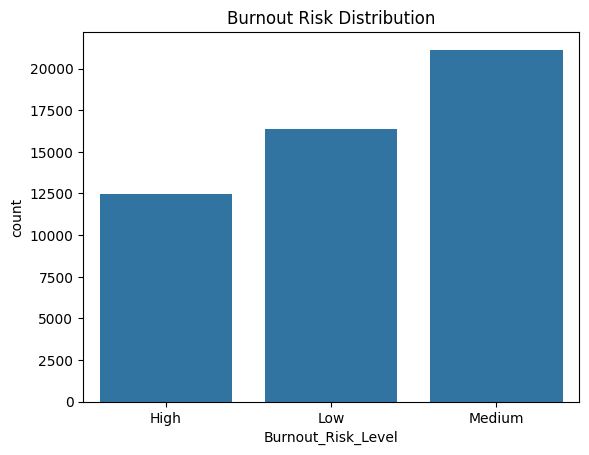

In [23]:
sns.countplot(x="Burnout_Risk_Level", data=df)

plt.title("Burnout Risk Distribution")
plt.show()

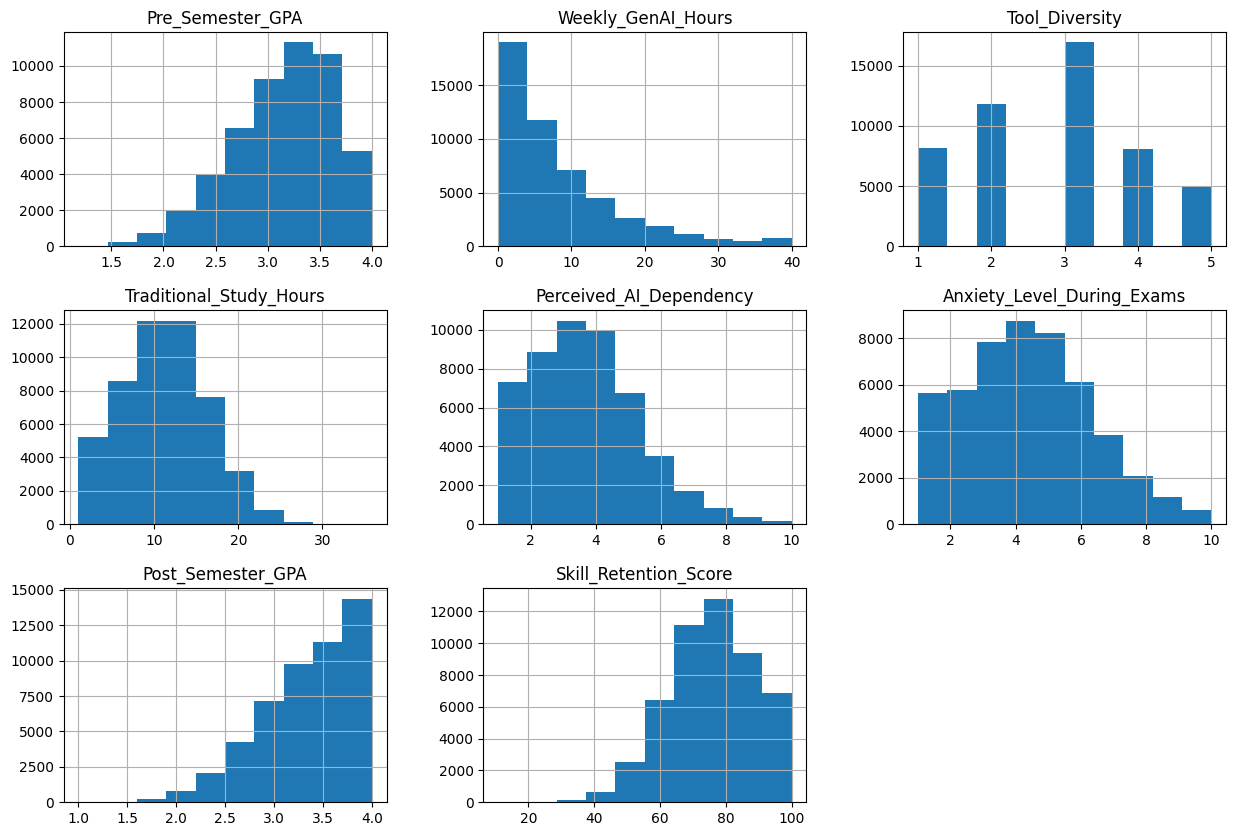

In [24]:
df.hist(figsize=(15,10))

plt.show()

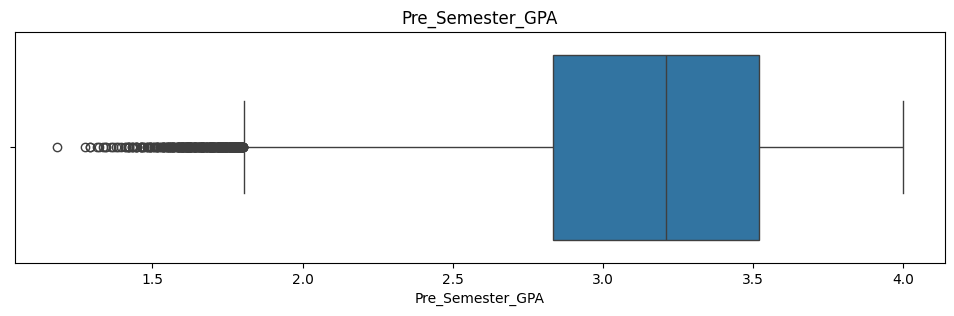

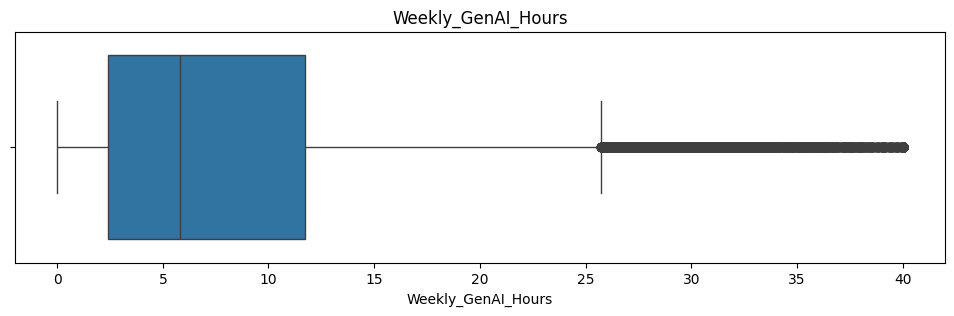

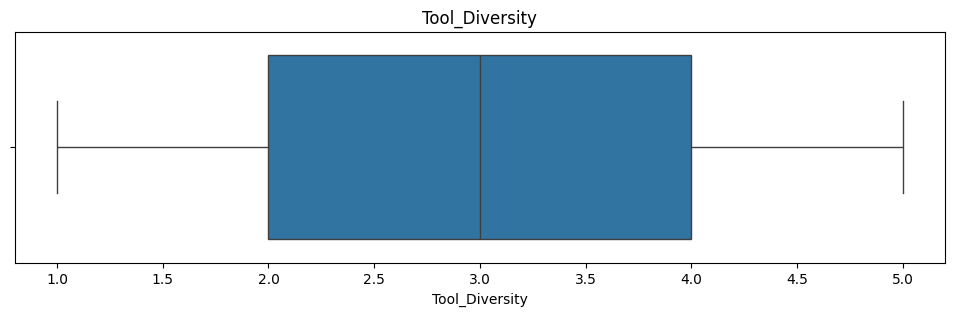

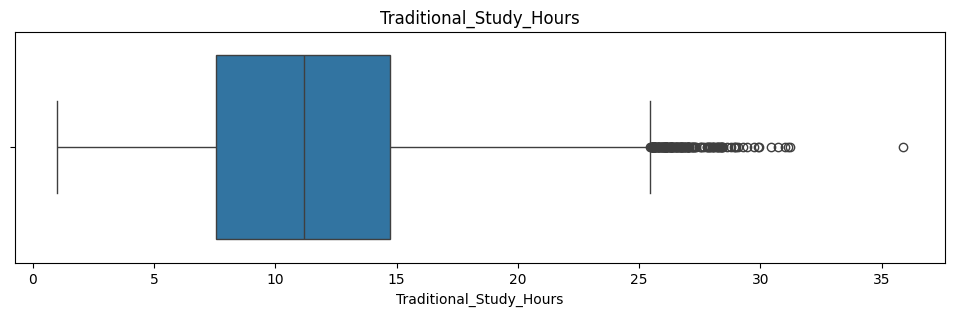

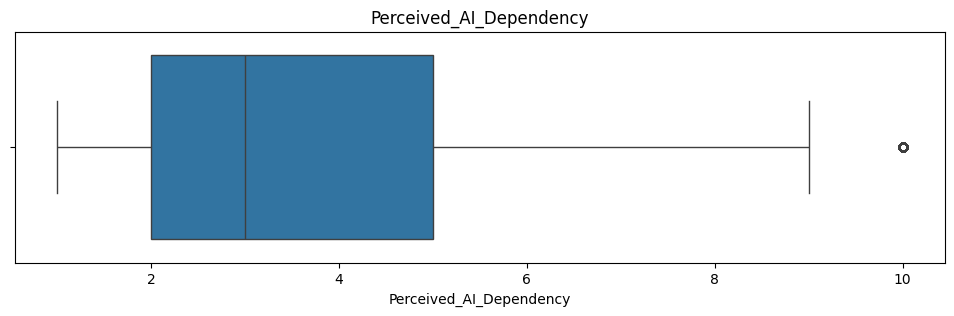

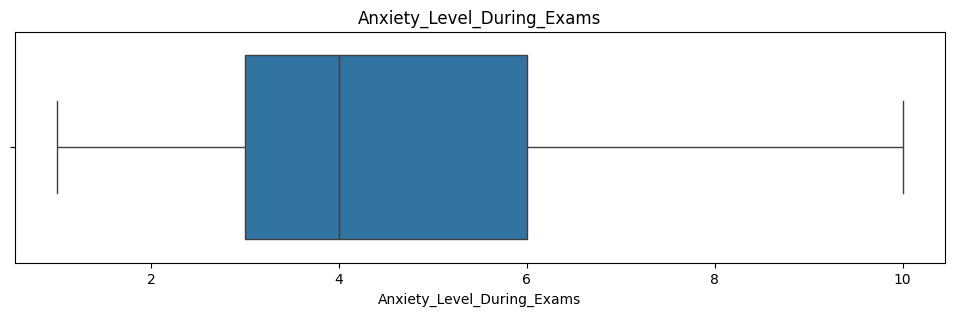

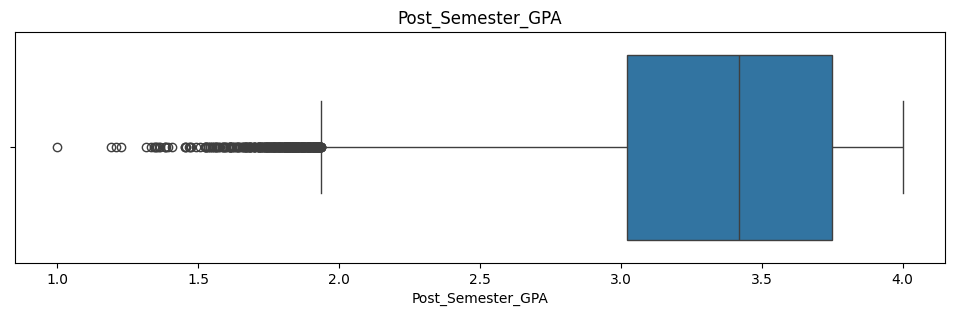

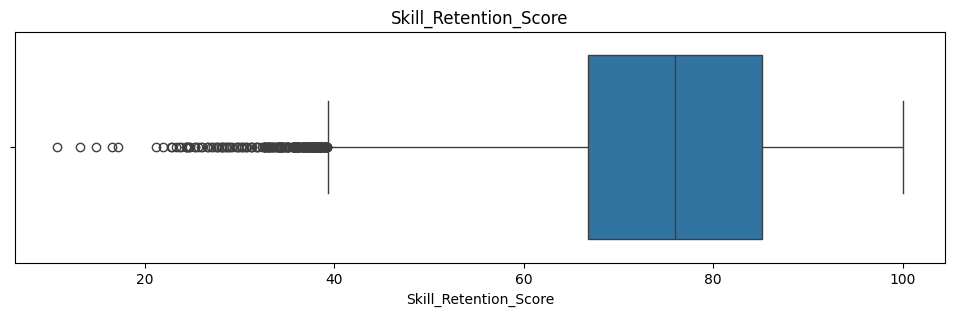

In [25]:
for col in df.select_dtypes(include=np.number).columns:
    plt.figure(figsize=(12,3))
    sns.boxplot(x=df[col])
    plt.title(col)
    plt.show()

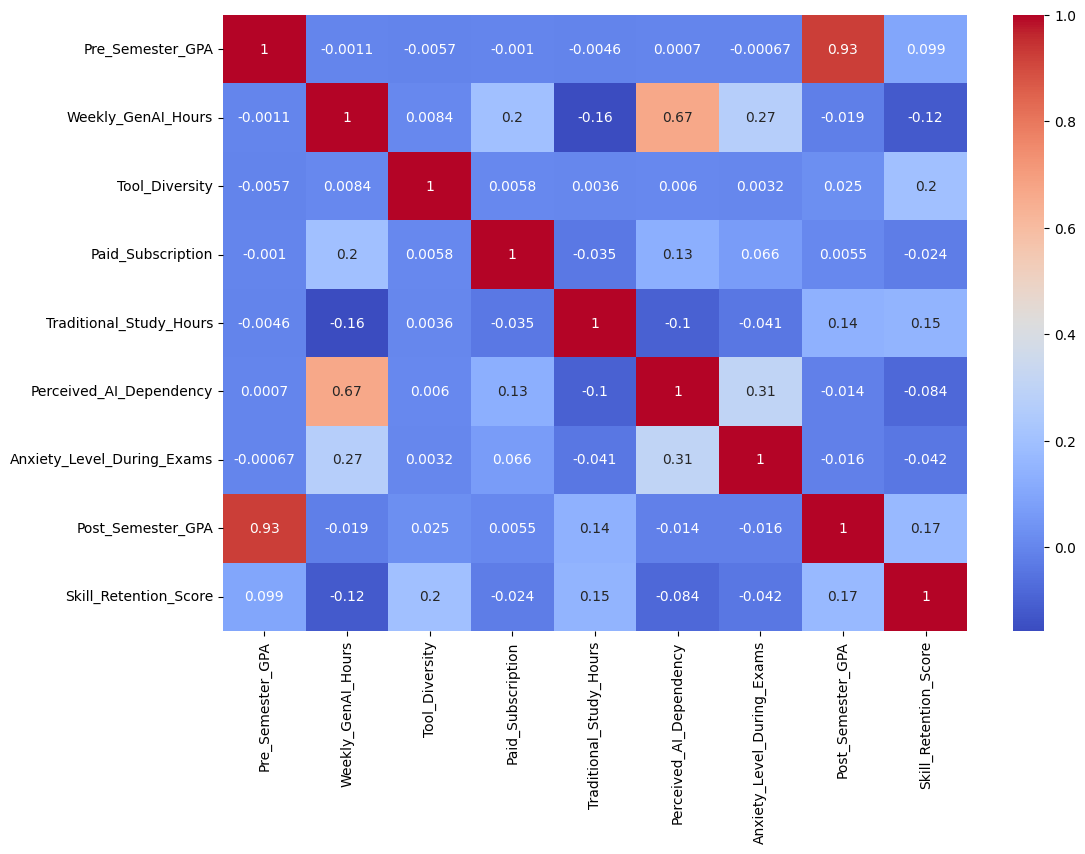

In [34]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.show()

## Model

Accuracy: 0.5271

              precision    recall  f1-score   support

        High       0.70      0.40      0.51      2497
         Low       0.54      0.46      0.49      3274
      Medium       0.48      0.66      0.55      4229

    accuracy                           0.53     10000
   macro avg       0.57      0.50      0.52     10000
weighted avg       0.55      0.53      0.52     10000



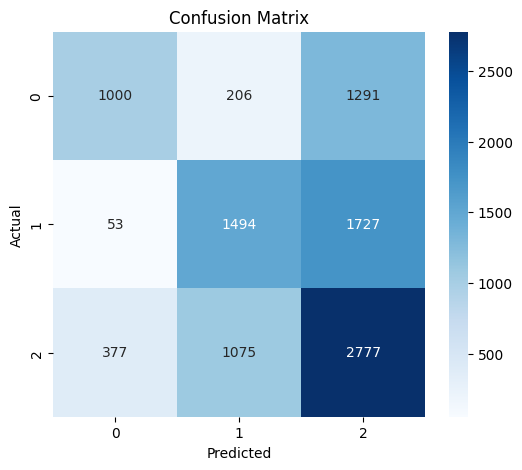

['student_burnout_svc_pipeline.pkl']

In [32]:
X = df.drop("Burnout_Risk_Level", axis=1)
y = df["Burnout_Risk_Level"]

categorical_cols = X.select_dtypes(include=["object"]).columns
numerical_cols = X.select_dtypes(exclude=["object"]).columns

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

model = SVC(kernel="rbf", C=1, gamma="scale", random_state=42)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", model)
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)



print("Accuracy:", accuracy_score(y_test, y_pred))
print()
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

joblib.dump(pipeline, "student_burnout_svc_pipeline.pkl")

## Key Insights

## Conclusions